# Análisis exploratorio del mercado de autos usados en Colombia
**Datos:** Guía de valores de Fasecolda (12.433 referencias de vehículos) · **Objetivo:** entender qué factores (marca, cilindraje, peso, año, etc.) influyen en el precio de un vehículo usado.

*Autores:* Juan Camilo Pulido Vargas y Sergio Alejandro Mora Guerrero ,· *Curso:* APRENDIZAJE AUTOMÁTICO (009841-P-1BG-2S-2026) · *Octubre 2026*

> **Nota sobre los datos:** los precios están en **miles de pesos colombianos** y hay una columna por año-modelo (`1970`…`2018`). Un valor de `0` significa que no hay precio para ese año-modelo.

## Paso 1 · Primer contacto: carga y *vibe check*

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

RUTA = "guia_fasecolda.csv"
if not os.path.exists(RUTA):            # en Colab: sube el archivo cuando lo pida
    from google.colab import files
    files.upload()

df = pd.read_csv(RUTA)
print(df.shape)
df[["Marca", "Clase", "Referencia1", "Peso", "Cilindraje", "Potencia", "2015", "2016", "2017", "2018"]].head()

(12433, 76)


,Marca,Clase,Referencia1,Peso,Cilindraje,Potencia,2015,2016,2017,2018
0,ALEKO,AUTOMOVIL,2141,1380,1570,82,0,0,0,12200
1,AMERICAN MOTOR,CAMIONETA PASAJ.,EAGLE,0,2351,0,0,0,0,43800
2,AMERICAN MOTOR,CAMPERO,WRANGLER,1100,2400,120,0,0,0,81600
3,AMERICAN MOTOR,CAMPERO,WRANGLER,1100,2400,120,0,0,0,74900
4,AUTECO,MOTOCICLETA,SUMA,75,80,6,0,0,0,2800


In [2]:
faltantes = df.isnull().sum()
faltantes[faltantes > 0]

HomologoCodigo    12433
TipoCaja            390
Nacionalidad         76
Combustible         726
Transmision         700
dtype: int64

In [3]:
# Los ceros también son "datos faltantes" disfrazados
print("Peso = 0:      ", (df["Peso"] == 0).sum())
print("Cilindraje = 0:", (df["Cilindraje"] == 0).sum())
print("Con precio 2017:", (df["2017"] > 0).sum(), "| con precio 2018:", (df["2018"] > 0).sum())

Peso = 0:       1805
Cilindraje = 0: 742
Con precio 2017: 1451 | con precio 2018: 12433


**Hallazgos**
- El dataset tiene **12.433 referencias y 76 columnas**. Mezcla autos, motos, camiones, remolques y buses, no solo automóviles.
- Faltantes reales: `HomologoCodigo` está 100 % vacía (se ignora); `Combustible` (726), `Transmision` (700), `TipoCaja` (390) y `Nacionalidad` (76) tienen algunos vacíos.
- Los ceros también son datos faltantes: `Peso` vale 0 en 1.805 filas y `Cilindraje` en 742 (en parte remolques, que no tienen motor).
- Solo **1.451** referencias tienen precio para el modelo 2017, frente a las 12.433 con precio 2018. Por eso en el Paso 4 se usan todos los años-modelo y no solo 2017.

## Paso 2 · Análisis univariado

In [4]:
# Precio del modelo 2017 (el cero significa "sin precio"), en miles de pesos
df["Precio_2017"] = df["2017"].replace(0, np.nan)
for c in ["Cilindraje", "Peso", "Potencia"]:
    df[c] = df[c].replace(0, np.nan)

df[["Precio_2017", "Cilindraje", "Peso", "Potencia"]].describe().round(0)

,Precio_2017,Cilindraje,Peso,Potencia
count,1451.0,11691.0,10628.0,11353.0
mean,109793.0,2749.0,2080.0,147.0
std,101856.0,2284.0,2189.0,91.0
min,2800.0,49.0,38.0,2.0
25%,47500.0,1498.0,1086.0,94.0
50%,80500.0,2000.0,1490.0,130.0
75%,140300.0,3497.0,2150.0,184.0
max,915000.0,15950.0,41000.0,662.0


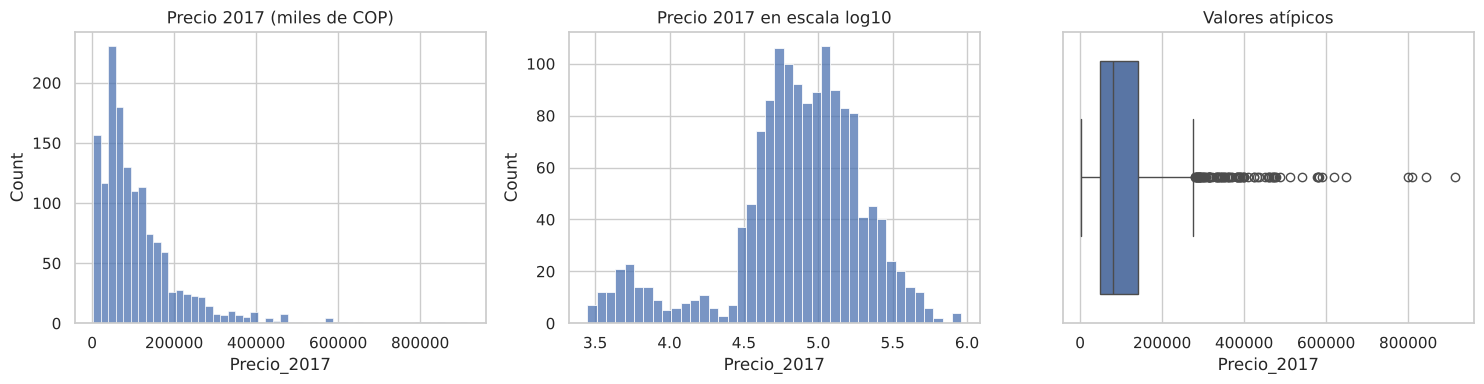

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(df["Precio_2017"].dropna(), bins=50, ax=ax[0])
ax[0].set_title("Precio 2017 (miles de COP)")
sns.histplot(np.log10(df["Precio_2017"].dropna()), bins=40, ax=ax[1])
ax[1].set_title("Precio 2017 en escala log10")
sns.boxplot(x=df["Precio_2017"].dropna(), ax=ax[2])
ax[2].set_title("Valores atípicos")
plt.tight_layout()
plt.show()

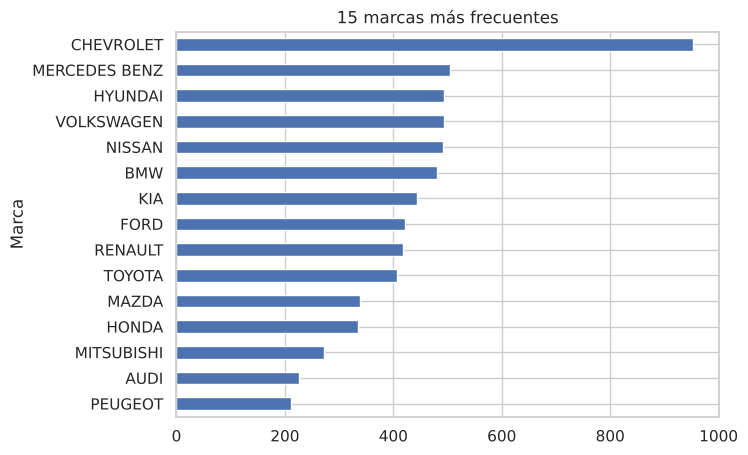

Clase
AUTOMOVIL                  3970
MOTOCICLETA                1491
CAMIONETA PASAJ.           1198
CAMPERO                    1182
FURGON                      768
CHASIS                      637
BUS / BUSETA / MICROBUS     503
CAMION                      464
Name: count, dtype: int64

In [6]:
df["Marca"].value_counts().head(15).sort_values().plot(kind="barh", figsize=(7, 5), title="15 marcas más frecuentes")
plt.show()
df["Clase"].value_counts().head(8)

**Hallazgos**
- El precio 2017 tiene mediana de ~80,5 millones y media de ~109,8 millones de pesos; el máximo es 915 millones. Esa diferencia entre media y mediana indica una distribución con cola larga a la derecha (asimetría 2,55).
- Unos 89 de 1.451 precios (≈6 %) son atípicos según la regla 1,5·IQR. En escala logarítmica la distribución se ve mucho más simétrica.
- Cilindraje: mediana de 1.998 cc; Peso: mediana de 1.490 kg (el máximo de 41.000 kg corresponde a vehículos pesados).
- Marcas más frecuentes: Chevrolet (953 referencias), Mercedes Benz (505), Hyundai (494), Volkswagen (493) y Nissan (492). Por clase dominan automóvil (3.970) y motocicleta (1.491).

## Paso 3 · Relaciones entre variables

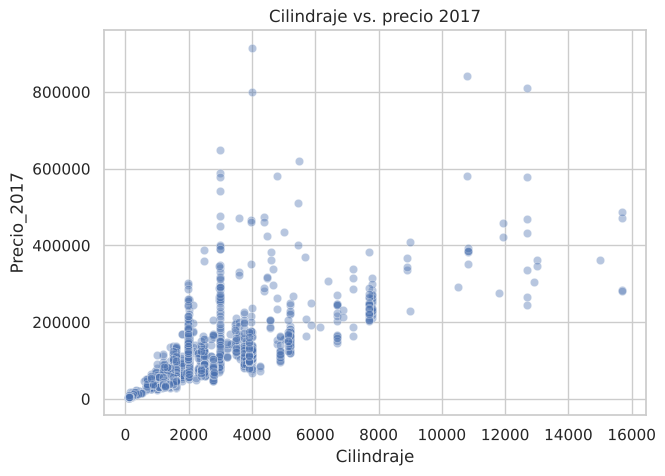

In [7]:
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x="Cilindraje", y="Precio_2017", alpha=0.4)
plt.title("Cilindraje vs. precio 2017")
plt.show()

In [8]:
# Precio promedio por marca (solo autos, camperos y camionetas; marcas con al menos 8 referencias con precio)
livianos_clases = ["AUTOMOVIL", "CAMPERO", "CAMIONETA PASAJ."]
g = df[df["Clase"].isin(livianos_clases)].groupby("Marca")["Precio_2017"].agg(["mean", "count"])
g[g["count"] >= 8]["mean"].sort_values(ascending=False).round(0).head(10)

Marca
PORSCHE          471758.0
MERCEDES BENZ    231912.0
LAND ROVER       227222.0
TOYOTA           207004.0
BMW              197678.0
AUDI             172629.0
JEEP             171362.0
VOLVO            171219.0
MITSUBISHI       126047.0
HONDA            118573.0
Name: mean, dtype: float64

In [9]:
# Peso promedio por marca (solo autos, para no mezclar con camiones y motos)
autos = df[df["Clase"] == "AUTOMOVIL"]
autos.groupby("Marca")["Peso"].agg(["mean", "count"]).query("count >= 20")["mean"].sort_values(ascending=False).round(0).head(10)

Marca
JAGUAR           1692.0
MERCEDES BENZ    1567.0
VOLVO            1533.0
BMW              1528.0
AUDI             1468.0
PORSCHE          1455.0
FORD             1338.0
TOYOTA           1290.0
PEUGEOT          1265.0
HONDA            1253.0
Name: mean, dtype: float64

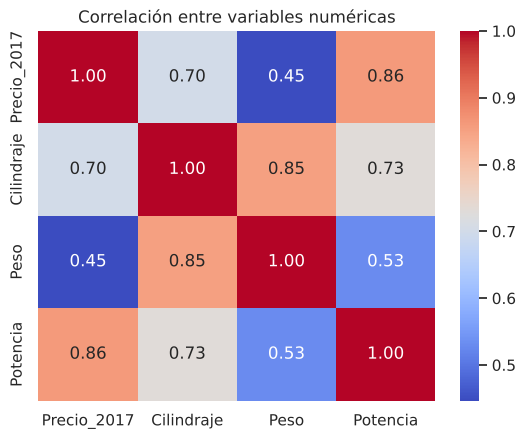

In [10]:
sns.heatmap(df[["Precio_2017", "Cilindraje", "Peso", "Potencia"]].corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlación entre variables numéricas")
plt.show()

**Hallazgos**
- Correlación con el precio 2017: **potencia 0,86**, cilindraje 0,70 y peso 0,45. La potencia es el mejor indicador del precio.
- Cilindraje y peso están muy correlacionados entre sí (0,85), así que aportan información parecida.
- Entre autos, camperos y camionetas (marcas con ≥8 referencias con precio), las de mayor precio promedio son Porsche (~472 millones), Mercedes Benz (~232), Land Rover (~227), Toyota (~207) y BMW (~198). Toyota está arriba probablemente por sus camperos de gama alta.
- Las más económicas son Renault (~51 millones), Hyundai (~57), Suzuki (~58) y Volkswagen (~60).
- Entre los autos, los más pesados en promedio son Jaguar, Mercedes Benz, Volvo, BMW y Audi (≈1,5 a 1,7 toneladas).

## Más allá

### 1. Enriquecimiento de datos
- **SOAT / accidentalidad:** permitiría saber si los modelos con más siniestros pierden valor más rápido.
- **Inflación y TRM:** el 84 % de las referencias son importadas, así que el dólar afecta directamente su precio.
- **DANE (ingreso, población por ciudad):** ayudaría a explicar la demanda y el precio por región.

### 2. Aprendizaje supervisado: predecir el precio

Filas: 26,964
R² (log precio): 0.969
Error absoluto medio: 9,477 miles de COP


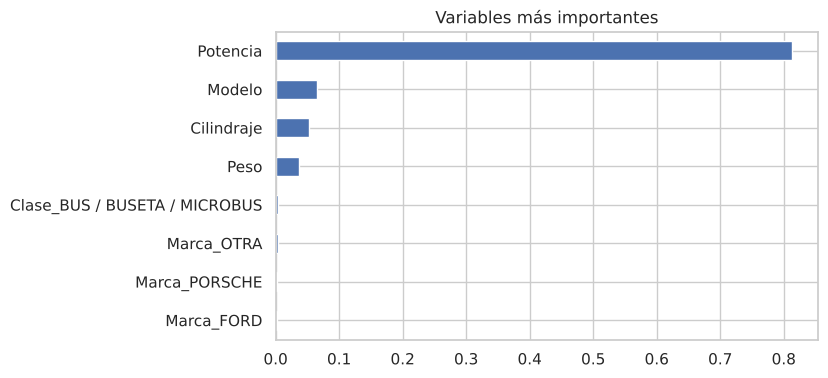

In [11]:
from sklearn.model_selection import GroupShuffleSplit
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error

# Formato largo: una fila por vehículo y año-modelo (2008-2018) con precio disponible
anios = [str(a) for a in range(2008, 2019)]
largo = df.melt(
    id_vars=["Codigo", "Marca", "Clase", "Cilindraje", "Peso", "Potencia", "Importado"],
    value_vars=anios, var_name="Modelo", value_name="Precio")
largo = largo[largo["Precio"] > 0].dropna(subset=["Cilindraje", "Peso", "Potencia"]).copy()
largo["Modelo"] = largo["Modelo"].astype(int)

# Marcas poco frecuentes se agrupan para no inflar las variables
top = largo["Marca"].value_counts().head(30).index
largo["Marca"] = largo["Marca"].where(largo["Marca"].isin(top), "OTRA")

X = pd.get_dummies(largo[["Marca", "Clase", "Cilindraje", "Peso", "Potencia", "Importado", "Modelo"]], columns=["Marca", "Clase"])
y = np.log(largo["Precio"])          # el precio es muy asimétrico: se predice en log

# Se separa por vehículo (Codigo) para que el mismo carro no aparezca en entrenamiento y prueba
tr, te = next(GroupShuffleSplit(test_size=0.2, random_state=42).split(X, y, groups=largo["Codigo"]))
rf = RandomForestRegressor(n_estimators=100, min_samples_leaf=3, n_jobs=-1, random_state=42).fit(X.iloc[tr], y.iloc[tr])
pred = rf.predict(X.iloc[te])

print(f"Filas: {len(largo):,}")
print(f"R² (log precio): {r2_score(y.iloc[te], pred):.3f}")
print(f"Error absoluto medio: {mean_absolute_error(np.exp(y.iloc[te]), np.exp(pred)):,.0f} miles de COP")
pd.Series(rf.feature_importances_, index=X.columns).nlargest(8).sort_values().plot(kind="barh", title="Variables más importantes", figsize=(7, 4))
plt.show()

**Hallazgos**
- Se usaron 26.964 observaciones (vehículo × año-modelo, 2008-2018). El conjunto de prueba contiene vehículos que el modelo nunca vio durante el entrenamiento.
- El modelo logra un **R² de 0,97** sobre el logaritmo del precio, con un error absoluto medio de ≈9,5 millones de pesos.
- Importancia de las variables: **potencia (81 %)**, año-modelo (6,5 %), cilindraje (5 %) y peso (3,7 %). Las marcas individuales aportan menos de 1 % cada una una vez se conoce la potencia.
- Cuidado al interpretar: el R² es alto en parte porque el conjunto mezcla desde motos hasta camiones, y la potencia separa muy bien esos segmentos. Un modelo solo para autos tendría una tarea más difícil. Además, potencia y cilindraje se solapan, así que la importancia se reparte entre ellas.

### 3. Aprendizaje no supervisado: segmentos de vehículos

In [12]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

cols = ["Cilindraje", "Peso", "Potencia", "Puertas", "CapacidadPasajeros"]
livianos = df[df["Clase"].isin(["AUTOMOVIL", "CAMPERO", "CAMIONETA PASAJ."])].copy()
livianos = livianos.dropna(subset=["Cilindraje", "Peso", "Potencia"])
Z = StandardScaler().fit_transform(livianos[cols])

for k in range(2, 7):
    print(k, "clusters → silhouette", round(silhouette_score(Z, KMeans(k, n_init=10, random_state=42).fit_predict(Z), sample_size=3000, random_state=42), 3))

2 clusters → silhouette 0.419
3 clusters → silhouette 0.419


4 clusters → silhouette 0.377
5 clusters → silhouette 0.322


6 clusters → silhouette 0.302


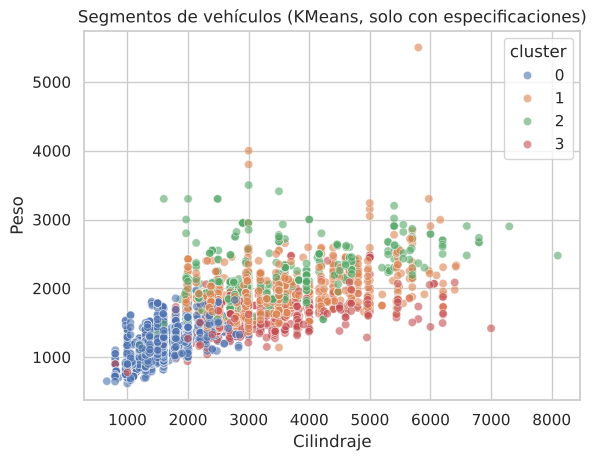

,n,cilindraje,peso,potencia,pasajeros,precio_2018,clase_frecuente,marcas_frecuentes
cluster,,,,,,,,
0,3265,1689.0,1215.0,115.0,5.0,51468.0,AUTOMOVIL,"RENAULT, CHEVROLET, HYUNDAI"
1,1093,3258.0,1834.0,245.0,5.0,150453.0,AUTOMOVIL,"BMW, MERCEDES BENZ, JEEP"
2,496,3365.0,2113.0,207.0,8.0,125050.0,CAMIONETA PASAJ.,"TOYOTA, NISSAN, MITSUBISHI"
3,627,2948.0,1520.0,225.0,4.0,156210.0,AUTOMOVIL,"BMW, MERCEDES BENZ, PORSCHE"


In [13]:
livianos["cluster"] = KMeans(4, n_init=10, random_state=42).fit_predict(Z)

sns.scatterplot(data=livianos, x="Cilindraje", y="Peso", hue="cluster", palette="deep", alpha=0.6)
plt.title("Segmentos de vehículos (KMeans, solo con especificaciones)")
plt.show()

# El precio NO se usó para agrupar: sirve para validar si los segmentos tienen sentido
perfil = livianos.groupby("cluster").agg(
    n=("Marca", "size"), cilindraje=("Cilindraje", "mean"), peso=("Peso", "mean"),
    potencia=("Potencia", "mean"), pasajeros=("CapacidadPasajeros", "mean"), precio_2018=("2018", "mean")).round(0)
perfil["clase_frecuente"] = livianos.groupby("cluster")["Clase"].agg(lambda s: s.value_counts().index[0])
perfil["marcas_frecuentes"] = livianos.groupby("cluster")["Marca"].agg(lambda s: ", ".join(s.value_counts().index[:3]))
perfil

**Hallazgos**
- Con KMeans sobre cilindraje, peso, potencia, puertas y pasajeros, el silhouette es mayor con 2 o 3 grupos (0,42) que con 4 (0,38). Se eligieron 4 porque dan segmentos más interpretables, aunque no están muy separados entre sí.
- **Grupo 0 (3.265 vehículos): City cars y económicos.** ~1.700 cc, 115 hp, precio 2018 ≈51 millones. Renault, Chevrolet, Hyundai.
- **Grupo 1 (1.093): SUVs y sedanes premium.** ~3.260 cc, 245 hp, ≈150 millones. BMW, Mercedes Benz, Jeep.
- **Grupo 2 (496): familiares grandes.** Camionetas de ~8 pasajeros, ~3.365 cc, 2.113 kg, ≈125 millones. Toyota, Nissan, Mitsubishi.
- **Grupo 3 (627): deportivos y de lujo de 4 plazas.** ~2.950 cc, 225 hp, ≈156 millones. BMW, Mercedes Benz, Porsche.
- El precio no se usó para agrupar, pero los grupos quedan ordenados por precio de forma coherente, lo que sugiere que los segmentos tienen sentido.

## Conclusiones
1. **La potencia es el factor que más pesa en el precio** (correlación 0,86 y 81 % de la importancia en el modelo). Cilindraje y peso influyen, pero en buena parte porque están ligados a la potencia.
2. **La marca importa como indicador de segmento**: Porsche, Mercedes Benz, BMW y Land Rover se ubican arriba y Renault, Hyundai y Suzuki abajo, pero una vez se conocen las especificaciones su aporte individual al modelo es pequeño.
3. **Un modelo de regresión predice bien el precio** (R² ≈ 0,97, error medio ≈ 9,5 millones), y **el clustering recupera segmentos reconocibles** (económicos, premium, familiares grandes y deportivos) sin usar el precio.
4. **Limitaciones y siguientes pasos:** hay muchos ceros que equivalen a datos faltantes, el dataset mezcla tipos de vehículo y la guía es de 2018. Enriquecer con TRM, inflación y SOAT permitiría modelar la depreciación en el tiempo.